<a href="https://colab.research.google.com/github/Ijlal40/Ijlal40.github.io/blob/master/DigitRecognition_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###IMPORTANT
It is heavily advised to change the runtime type to the T4 GPU instead of the standard CPU as it will heavily cut down on the total runtime of the code significantly.

This can be done by going to Runtime > Change Runtime Type > T4 GPU

In [ ]:
#installing mnist database
from keras.datasets import mnist

from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import matplotlib.pyplot as plt

from keras.utils import to_categorical
from keras.models import Sequential, Model

#Fixing the random seed for reproducibility purposes
static_seed = 2
np.random.seed(static_seed)

# labels to help represent each digit during the visualisation portion
digit_labels = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

(x_train, y_train), (x_test, y_test) = mnist.load_data() #loading and splitting data respetively via MNIST functions

#Normalizing the data
x_train = x_train / 255.0
x_test = x_test / 255.0

#One-hot encoding
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

print("Train image shape ", x_train.shape)
print("Test image shape ", x_test.shape)

Train image shape  (60000, 28, 28)
Test image shape  (10000, 28, 28)


In [ ]:
#Creating LSTM model for MNIST recognition
model = keras.Sequential()
model.add(layers.LSTM(32, input_shape=(x_train.shape[1], x_train.shape[2]), return_sequences=True))
model.add(layers.LSTM(32))
model.add(layers.Dense(10, activation='softmax'))

#Printing model summary which contains info about each layer and total parameters
print(model.summary())

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 28, 32)            7808      
                                                                 
 lstm_1 (LSTM)               (None, 32)                8320      
                                                                 
 dense (Dense)               (None, 10)                330       
                                                                 
Total params: 16458 (64.29 KB)
Trainable params: 16458 (64.29 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


In [ ]:
#Compiling the LSTM model with an appropriate loss and optimizer.
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [ ]:
#Fitting the model with training data provided
model.fit(x_train, y_train, validation_split=0.2, batch_size=64, epochs=20)

#Evaluation of model
score = model.evaluate(x_test, y_test, verbose=0)
print("Total NN Error after epoch training: %.2f%%" % (100-score[1]*100))

Epoch 1/20
750/750 [==============================] - 16s 13ms/step - loss: 0.7114 - accuracy: 0.7733 - val_loss: 0.2856 - val_accuracy: 0.9159
Epoch 2/20
750/750 [==============================] - 6s 8ms/step - loss: 0.2207 - accuracy: 0.9353 - val_loss: 0.1637 - val_accuracy: 0.9512
Epoch 3/20
750/750 [==============================] - 6s 8ms/step - loss: 0.1470 - accuracy: 0.9560 - val_loss: 0.1271 - val_accuracy: 0.9621
Epoch 4/20
750/750 [==============================] - 5s 7ms/step - loss: 0.1150 - accuracy: 0.9662 - val_loss: 0.1077 - val_accuracy: 0.9675
Epoch 5/20
750/750 [==============================] - 6s 9ms/step - loss: 0.0892 - accuracy: 0.9734 - val_loss: 0.0940 - val_accuracy: 0.9716
Epoch 6/20
750/750 [==============================] - 5s 7ms/step - loss: 0.0771 - accuracy: 0.9772 - val_loss: 0.0828 - val_accuracy: 0.9755
Epoch 7/20
750/750 [==============================] - 5s 7ms/step - loss: 0.0684 - accuracy: 0.9797 - val_loss: 0.0788 - val_accuracy: 0.9768
Epoc

1/1 [==============================] - 1s 882ms/step

Predicted digit by the NN model: 9
Actual digit according to dataset: 9


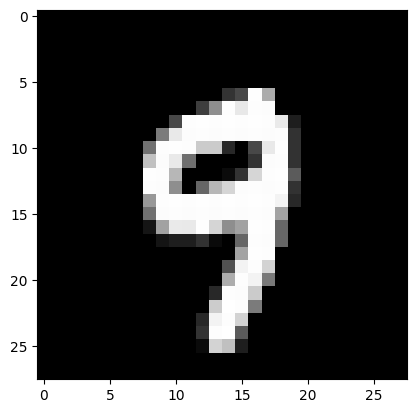

1/1 [==============================] - 0s 18ms/step

Predicted digit by the NN model: 3
Actual digit according to dataset: 3


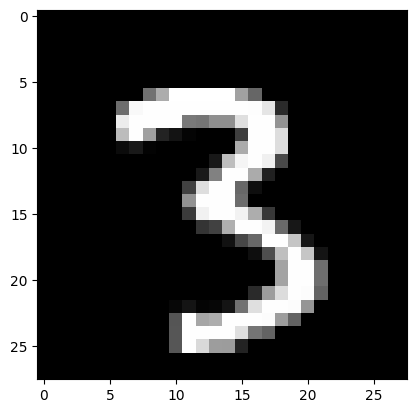

1/1 [==============================] - 0s 21ms/step

Predicted digit by the NN model: 4
Actual digit according to dataset: 4


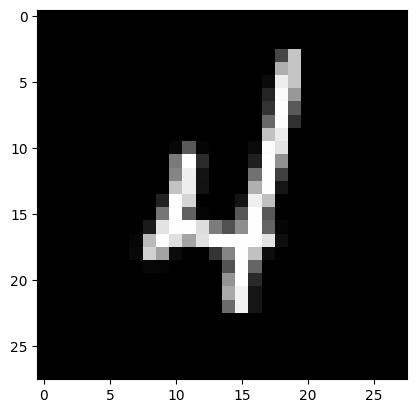

1/1 [==============================] - 0s 21ms/step

Predicted digit by the NN model: 4
Actual digit according to dataset: 4


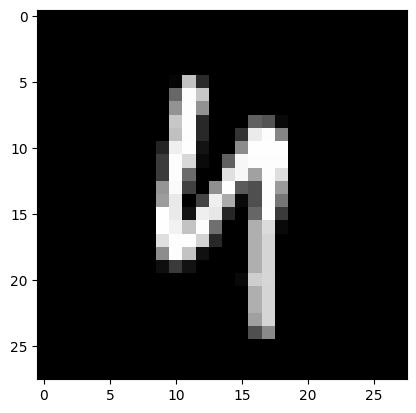

1/1 [==============================] - 0s 19ms/step

Predicted digit by the NN model: 6
Actual digit according to dataset: 6


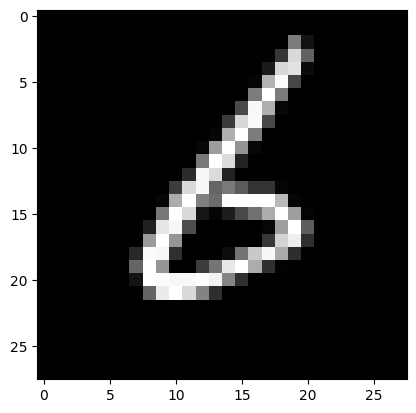

1/1 [==============================] - 0s 19ms/step

Predicted digit by the NN model: 3
Actual digit according to dataset: 3


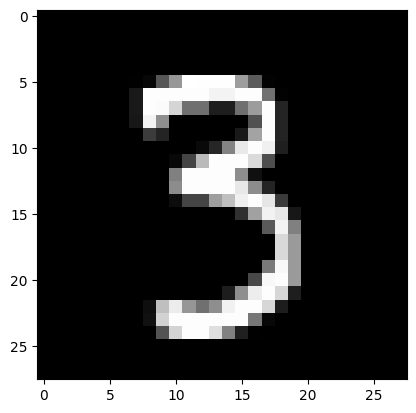

1/1 [==============================] - 0s 17ms/step

Predicted digit by the NN model: 5
Actual digit according to dataset: 5


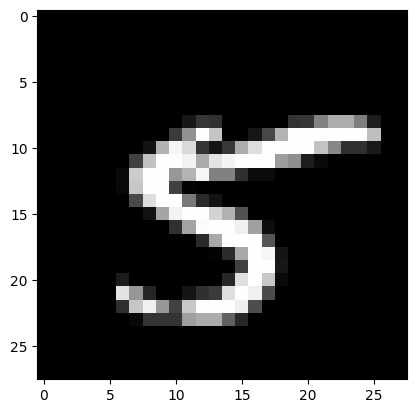

1/1 [==============================] - 0s 21ms/step

Predicted digit by the NN model: 1
Actual digit according to dataset: 1


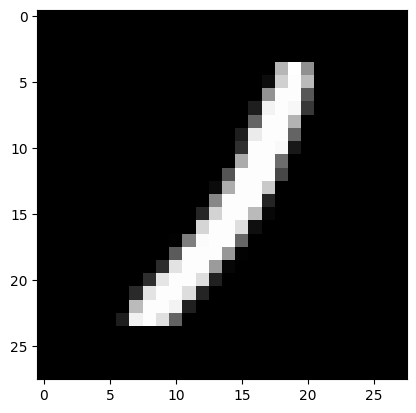

1/1 [==============================] - 0s 19ms/step

Predicted digit by the NN model: 5
Actual digit according to dataset: 5


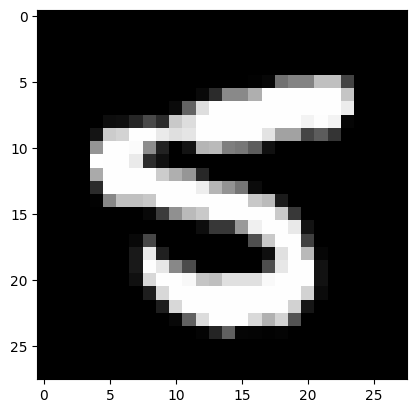

1/1 [==============================] - 0s 20ms/step

Predicted digit by the NN model: 2
Actual digit according to dataset: 2


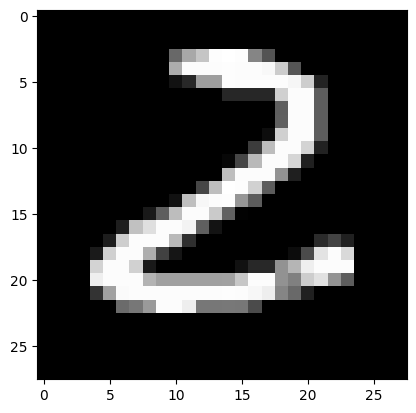

In [ ]:
#Loop to create various objects
for i in range(0,10):
  #Grabbing any random sample from the testing MNIST set
  sample_num = np.random.randint(0, 10000)
  sample_img = x_test[sample_num].reshape(28,28)

  #Inputting the test input for prediction processing
  predicted_digit = np.argmax(model.predict(x_test[sample_num][None]))
  actual_digit = np.argmax(y_test[sample_num])

  #Print out both the results and image from the dataset itself to the user
  print("\nPredicted digit by the NN model: " + str(digit_labels[predicted_digit]))
  print("Actual digit according to dataset: " + str(digit_labels[actual_digit]))
  plt.imshow(sample_img, cmap='gray')
  plt.show()